In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import cv2

In [2]:
# Exibe uma janela para a seleção de um arquivo
from google.colab import files
arquivo = files.upload()
img_name = next(iter(arquivo))

# Leitura da imagem pelo cv2, convertido para tons de cinza
imagem = cv2.imread(img_name, cv2.IMREAD_GRAYSCALE)

Saving Lenna.png to Lenna.png


In [ ]:

import cv2
import numpy as np
import random

def ruidoSP(imagem, prob):

   saida = imagem.copy()
   limiar = 1 - prob

   for i in range(imagem.shape[0]):
       for j in range(imagem.shape[1]):

            rdn = random.random()
            if rdn < prob:
                saida[i][j] = 0

            elif rdn > limiar:
                saida[i][j] = 255

   return saida

ruidosa = ruidoSP(imagem, 0.05)
plt.imshow(ruidosa,  cmap='gray')

In [4]:
# Criação do kernel de média
mean = np.array(([1, 1, 1],
                 [1, 1, 1],
                 [1, 1, 1]), dtype=float)
# Cada valor da matriz é dividido pela somatoria dos elementos
# Essencialmente, o cálculo da média.
mean = mean / np.sum(mean)
print(mean)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [5]:
# Criação do kernel gaussiano
gaussian = np.array(([1, 2, 1],
                     [2, 4, 2],
                     [1, 2, 1]), dtype=float)
# Cada valor da matriz é dividido pela somatoria dos elementos
gaussian = gaussian / np.sum(gaussian)
print(gaussian)

[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]


In [44]:
# Criação do kernel laplaciano (realce)
laplaciano = np.array(([0, 1, 0],
                       [1, -4, 1],
                       [0, 1, 0]), dtype=float)
print(laplaciano)

[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]


In [45]:
# Criação do unsharp mask (realce)
unsharp = np.array(([0, -1, 0],
                    [-1, 5, -1],
                    [0, -1, 0]), dtype=float)
print(unsharp)

[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


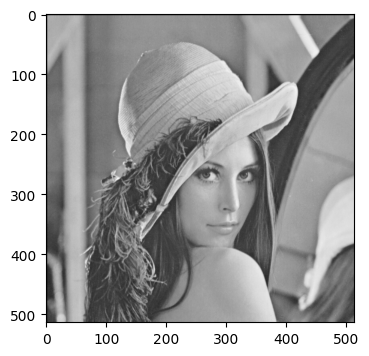

In [8]:
altura, largura = imagem.shape
imagem_padded = np.zeros((altura + 2, largura + 2))

# Copiar a imagem original para o centro
imagem_padded[2:altura + 2, 2:largura + 2] = imagem

plt.figure(figsize=(4,4))
plt.imshow(imagem_padded, cmap='gray')

In [34]:
# Imagem de saída
saida = np.zeros((altura, largura), dtype=np.float32)

In [10]:
# Convolução para média
for i in range(altura):
    for j in range(largura):

        # Extrair a região 3x3
        regiao = imagem_padded[i:i+3, j:j+3]
        # Multiplicação elemento a elemento
        mult_mean = regiao * mean
        # Somar todos os valores
        valor_mean = np.sum(mult_mean)
        # Guardar o resultado
        saida[i, j] = valor_mean

saida_mean = saida.astype(np.uint8)

In [18]:
# Convolução para gaussiana
for i in range(altura):
    for j in range(largura):

        # Extrair a região 3x3
        regiao = imagem_padded[i:i+3, j:j+3]
        # Multiplicação elemento a elemento
        mult_gauss = regiao * gaussian
        # Somar todos os valores
        valor_gauss = np.sum(mult_gauss)

        # Guardar o resultado
        saida[i, j] = valor_gauss

saida = saida.astype(np.uint8)

In [40]:

# Convolução para laplace
for i in range(altura):
    for j in range(largura):

        # Extrair a região 3x3
        regiao = imagem_padded[i:i+3, j:j+3]
        # Multiplicação elemento a elemento
        mult_laplace = regiao * laplaciano
        # Somar todos os valores
        valor_laplace = np.sum(mult_laplace)

        # Guardar o resultado
        saida[i, j] = valor_laplace


fator = 0.5
realce = imagem.astype(np.float32) - (fator * saida)
realce = np.clip(realce, 0, 255).astype(np.uint8)

In [53]:

# Convolução para unsharp mask
for i in range(altura):
    for j in range(largura):

        # Extrair a região 3x3
        regiao = imagem_padded[i:i+3, j:j+3]
        # Multiplicação elemento a elemento
        mult_unsharp = regiao * unsharp
        # Somar todos os valores
        valor_unsharp = np.sum(mult_unsharp)

        # Guardar o resultado
        saida[i, j] = valor_unsharp

realce = np.clip(saida, 0, 255).astype(np.uint8)

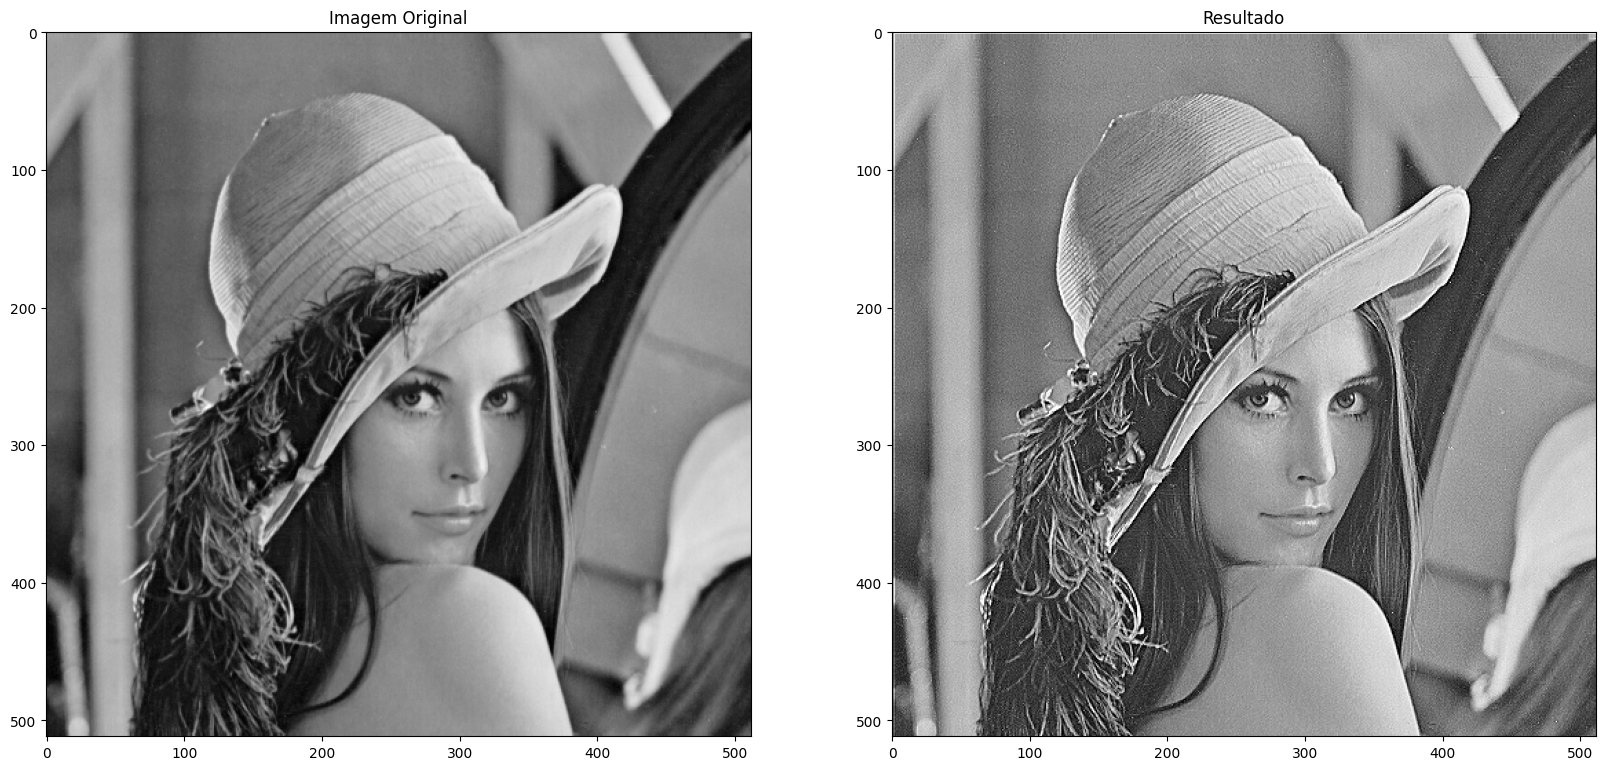

In [54]:
plt.figure(figsize=(20, 20))

plt.subplot(1, 2, 1)
plt.imshow(imagem, cmap='gray')
plt.title('Imagem Original')

plt.subplot(1, 2, 2)
plt.imshow(realce, cmap='gray')
plt.title('Resultado')

plt.show()